
# FMCE for NLP — Phase 1 (IMDB + BERT + FMCS Dataset to Google Drive)

This Colab notebook does **Phase 1 only**:

1. Mount Google Drive  
2. Load IMDB dataset (sentiment classification)  
3. Fine-tune `bert-base-uncased` on IMDB  
4. Track validation loss per epoch, compute **smoothed loss** & **CQI**  
5. Split training into **K phases** using equal segments on log-smoothed loss  
6. From a chosen BERT layer (e.g. layer 6) extract hidden representations  
7. Construct an **FMCS dataset** (features + phase labels)  
8. Save all FMCS data to **Google Drive** for later FMCE experiments


In [2]:

#@title 🔐 Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:

#@title 📦 Install dependencies
import sys, subprocess, torch

!pip install -U "transformers>=4.44.0" "datasets>=2.19.0" "accelerate>=0.34.0" "evaluate>=0.4.1"


def pip_install(pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + pkgs)

print("Python version:", sys.version)
print("CUDA available:", torch.cuda.is_available())

pip_install([
    "transformers>=4.44.0",
    "datasets>=2.19.0",
    "accelerate>=0.34.0",
    "evaluate>=0.4.1",
    "scikit-learn",
    "matplotlib",
    "tqdm",
    "scipy"
])

import numpy as np, random
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.6/511.6 kB 45.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 60.0 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.0.0
    Uninstalling datasets-4.0.0:
      Successfully uninstalled datasets-4.0.0
Python version: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
CUDA available: True


In [37]:

#@title ⚙️ Config

from dataclasses import dataclass

@dataclass
class Config:
    train_epochs: int = 15
    K_phases: int = 5     # 例如切 10 段，每 5 个 epoch 一段
    max_length: int = 128
    train_batch_size: int = 256
    eval_batch_size: int = 256
    lr: float = 1e-4       # 和上面的 optimizer 保持一致就行
    model_name: str = "bert-base-uncased"             # number of FMCS phases
    target_layer: int = -1            # encoder layer index for feature extraction (1..12)
    subsample_train: int = 8000      # subset for speed; set None for full
    subsample_val: int = 2000
    extract_subset: int = None       # how many train samples to use for FMCS dataset
    feature_pooling: str = "mean"    # "mean" or "cls"
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    drive_dir: str = "/content/drive/MyDrive/ExplainableNLP/FMCE_dataset_30"

CFG = Config()
CFG


Config(train_epochs=15, K_phases=5, max_length=128, train_batch_size=256, eval_batch_size=256, lr=0.0001, model_name='bert-base-uncased', target_layer=-1, subsample_train=8000, subsample_val=2000, extract_subset=None, feature_pooling='mean', device='cuda', drive_dir='/content/drive/MyDrive/ExplainableNLP/FMCE_dataset_30')

In [5]:
#@title 📚 Load Yahoo! Answers Topics (efficient version: split first, then map)

from datasets import load_dataset, ClassLabel

# 加载原始数据
raw = load_dataset("yahoo_answers_topics")
print(raw)  # train: 1.4M, test: 60k

# 步骤 1：把 label 列转换成 ClassLabel（否则不能 stratify）
def convert_label_to_classlabel(ds):
    # 原字段是整数 0-9
    unique_labels = sorted(list(set(ds["topic"])))
    class_label = ClassLabel(num_classes=len(unique_labels), names=[str(i) for i in unique_labels])
    ds = ds.cast_column("topic", class_label)
    return ds

raw["train"] = convert_label_to_classlabel(raw["train"])
raw["test"]  = convert_label_to_classlabel(raw["test"])


# 步骤 2：先 split（快），后 map（更快，因为只对 100k 做 map）
splits = raw["train"].train_test_split(
    test_size=0.1,
    seed=42,
    stratify_by_column="topic"   # 现在可以用了
)

train_all = splits["train"]
val_ds    = splits["test"]

print("Train_all:", len(train_all))
print("Val:", len(val_ds))

# 步骤 3：可选 subsample（减少训练集规模，让训练慢一点）
# max_train_samples = 100_000   # 建议 50k~100k
# if len(train_all) > max_train_samples:
#     train_all = train_all.shuffle(seed=42).select(range(max_train_samples))
#     print(f"⚡ Subsampled train_all → {len(train_all)} samples")

# 步骤 3：不再 subsample，直接用全量 train_all
print(f"Using full train_all: {len(train_all)} samples")


# 步骤 4：map 用在 subsample 后的数据（省时 ×20）
def merge_text(example):
    title = example.get("question_title", "")
    content = example.get("question_content", "")
    answer = example.get("best_answer", "")
    example["text"] = " ".join([title, content, answer]).strip()
    example["label"] = int(example["topic"])
    return example

train_ds = train_all.map(merge_text, remove_columns=["id", "question_title", "question_content", "best_answer", "topic"])
val_ds   = val_ds.map(merge_text, remove_columns=["id", "question_title", "question_content", "best_answer", "topic"])

print(train_ds)
print(val_ds)
print("Train labels sample:", train_ds["label"][:20])
print("Val labels sample:", val_ds["label"][:20])

#@title ✂️ Tokenize Yahoo! Answers

from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(CFG.model_name, use_fast=True)

def preprocess(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding=False,
        max_length=CFG.max_length,
    )

train_enc = train_ds.map(preprocess, batched=True, remove_columns=["text"])
val_enc   = val_ds.map(preprocess,   batched=True, remove_columns=["text"])

# 告诉 datasets 这些列要转成 torch.Tensor
cols = ["input_ids", "attention_mask", "label"]
train_enc.set_format(type="torch", columns=cols)
val_enc.set_format(type="torch", columns=cols)

print("Encoded train size:", len(train_enc))
print("Encoded val size:", len(val_enc))
print(train_enc[0])


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

yahoo_answers_topics/train-00000-of-0000(…):   0%|          | 0.00/241M [00:00<?, ?B/s]

yahoo_answers_topics/train-00001-of-0000(…):   0%|          | 0.00/270M [00:00<?, ?B/s]

yahoo_answers_topics/test-00000-of-00001(…):   0%|          | 0.00/21.9M [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1260000 [00:00<?, ? examples/s]

Map:   0%|          | 0/140000 [00:00<?, ? examples/s]

Encoded train size: 1260000
Encoded val size: 140000
{'label': tensor(0), 'input_ids': tensor([  101,  2129,  2079,  2647,  2111,  4377,  1029, 13367,  1996,  5156,
         2100,  4929,  4253,  1012,   102]), 'attention_mask': tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])}


In [6]:
# #@title 📚 Load DBpedia-14 dataset (random split, optional 200k subsample)
# from datasets import load_dataset

# raw = load_dataset("dbpedia_14")
# print(raw)

# # 先统一成有 text 字段
# def ensure_text_column(ds):
#     cols = ds.column_names

#     if "text" in cols:
#         return ds

#     if "title" in cols and "content" in cols:
#         def _merge(example):
#             example["text"] = example["title"] + " " + example["content"]
#             return example
#         ds = ds.map(_merge, remove_columns=[c for c in ["title", "content"] if c in cols])
#         return ds

#     if "content" in cols:
#         return ds.rename_column("content", "text")

#     raise ValueError(f"Unexpected columns: {cols}")

# train_all = ensure_text_column(raw["train"])
# test_ds   = ensure_text_column(raw["test"])

# # ✅ 用 train_test_split 随机划分 9:1（按 label 分层，避免类别分布问题）
# splits = train_all.train_test_split(
#     test_size=0.1,
#     seed=42,
#     stratify_by_column="label"
# )
# train_ds = splits["train"]
# val_ds   = splits["test"]

# print("Raw Train size:", len(train_ds))
# print("Raw Val size:", len(val_ds))

# # ✅ 可选：在“打乱后的完整 train_ds”里随机抽 200k
# max_train_samples = 100_000
# if len(train_ds) > max_train_samples:
#     train_ds = train_ds.shuffle(seed=42).select(range(max_train_samples))
#     print(f"⚡ Subsampled train_ds to {len(train_ds)} samples (random).")
# else:
#     print("train_ds smaller than max_train_samples; no subsampling.")

# print("Final Train size:", len(train_ds))
# print("Val size:", len(val_ds))
# print("Test size:", len(test_ds))

# #@title ✂️ Tokenize
# from transformers import AutoTokenizer

# tokenizer = AutoTokenizer.from_pretrained(CFG.model_name, use_fast=True)

# def preprocess(examples):
#     return tokenizer(
#         examples["text"],
#         truncation=True,
#         padding=False,
#         max_length=CFG.max_length
#     )

# train_enc = train_ds.map(preprocess, batched=True, remove_columns=["text"])
# val_enc   = val_ds.map(preprocess,   batched=True, remove_columns=["text"])

# cols = ["input_ids", "attention_mask", "label"]
# train_enc.set_format(type="torch", columns=cols)
# val_enc.set_format(type="torch", columns=cols)

# len(train_enc), len(val_enc)


In [7]:
# #@title 📚 Load IMDB dataset (full train, 9:1 split, no subsampling)
# from datasets import load_dataset

# raw = load_dataset("imdb")
# print(raw)

# # 原始 IMDb:
# #   train: 25000
# #   test:  25000
# #   unsupervised: 50000 (无标签，一般不用做分类)
# train_all = raw["train"]
# test_ds   = raw["test"]

# # 9:1 划分 train / val
# val_ratio = 0.1
# val_size = int(len(train_all) * val_ratio)   # 2500
# train_size = len(train_all) - val_size      # 22500

# train_ds = train_all.select(range(0, train_size))             # 前 22500
# val_ds   = train_all.select(range(train_size, len(train_all)))# 后 2500

# print("Train size:", len(train_ds))
# print("Val size:", len(val_ds))
# print("Test size:", len(test_ds))


In [8]:
# #@title 📚 Load AG News dataset (full train, 9:1 split, no subsampling)
# from datasets import load_dataset

# raw = load_dataset("ag_news")
# print(raw)

# train_all = raw["train"]    # ~120k
# test_ds   = raw["test"]     # ~7.6k

# # 9:1 划分 train / val
# val_ratio = 0.1
# val_size = int(len(train_all) * val_ratio)
# train_size = len(train_all) - val_size

# # 这里假设数据集有 'text' 字段，如果是 'title' + 'description' 也兼容一下
# def ensure_text_column(ds):
#     cols = ds.column_names
#     if "text" in cols:
#         return ds
#     elif "title" in cols and "description" in cols:
#         # 拼成一个 text 字段
#         def _merge(example):
#             example["text"] = example["title"] + " " + example["description"]
#             return example
#         ds = ds.map(_merge)
#         return ds.remove_columns([c for c in ["title", "description"] if c in cols])
#     else:
#         raise ValueError(f"Unexpected columns: {cols}")

# train_all = ensure_text_column(train_all)

# train_ds = train_all.select(range(0, train_size))
# val_ds   = train_all.select(range(train_size, len(train_all)))

# print("Train size:", len(train_ds))
# print("Val size:", len(val_ds))
# print("Test size:", len(test_ds))


In [9]:

# #@title ✂️ Tokenize
# from transformers import AutoTokenizer

# tokenizer = AutoTokenizer.from_pretrained(CFG.model_name, use_fast=True)

# def preprocess(examples):
#     return tokenizer(examples["text"], truncation=True, padding=False, max_length=CFG.max_length)

# train_enc = train_ds.map(preprocess, batched=True, remove_columns=["text"])
# val_enc   = val_ds.map(preprocess,   batched=True, remove_columns=["text"])

# cols = ["input_ids", "attention_mask", "label"]
# train_enc.set_format(type="torch", columns=cols)
# val_enc.set_format(type="torch", columns=cols)

# len(train_enc), len(val_enc)


In [10]:
#@title 🤗 Fine-tune BERT (manual loop) & record epoch losses

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding
from transformers import BertConfig, BertForSequenceClassification


# # 1. pretrain BERT
# model = AutoModelForSequenceClassification.from_pretrained(
#     CFG.model_name,
#     num_labels=2
# ).to(CFG.device)

# # 提示是正常的：classifier.* 是新初始化的，下游任务要训练它
# print("Model loaded on", CFG.device)

# 1. 自定义一个小 BERT，从零随机初始化
mini_config = BertConfig(
    vocab_size=tokenizer.vocab_size,
    hidden_size=256,            # 🔺 更宽一点
    num_hidden_layers=3,        # 🔺 4 层 encoder
    num_attention_heads=4,      # 256 / 4 = 64 维/头，刚好整除
    intermediate_size=1024,     # 通常 4 * hidden_size
    num_labels=10,
    hidden_dropout_prob=0.2,    # 稍微小一点，有利于收敛
    attention_probs_dropout_prob=0.2,
)



model = BertForSequenceClassification(mini_config).to(CFG.device)
print(
    f"Randomly initialized mini-BERT "
    f"({mini_config.num_hidden_layers} layers, hidden={mini_config.hidden_size}) on {CFG.device}"
)




Randomly initialized mini-BERT (3 layers, hidden=256) on cuda


In [11]:
# 2. DataCollator + DataLoader（动态 padding）
data_collator = DataCollatorWithPadding(tokenizer)

train_loader = DataLoader(
    train_enc,
    batch_size=CFG.train_batch_size,
    shuffle=True,
    collate_fn=data_collator,
)
val_loader = DataLoader(
    val_enc,
    batch_size=CFG.eval_batch_size,
    shuffle=False,
    collate_fn=data_collator,
)

# 3. 优化器
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,            # 🔻 从 1e-4 降到 3e-5，让收敛更慢更平滑
    betas=(0.9, 0.999),
    weight_decay=0.05,
)

# 🟩 AMP scaler + 计时
from torch.cuda.amp import GradScaler, autocast
import time

scaler = GradScaler()

epoch_logs = {"val_loss": [], "val_acc": [], "train_acc": []}

def evaluate_one_epoch():
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(CFG.device)
            attention_mask = batch["attention_mask"].to(CFG.device)
            labels = batch["labels"] if "labels" in batch else batch["label"]
            labels = labels.to(CFG.device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
            )
            loss = outputs.loss
            logits = outputs.logits

            total_loss += loss.item() * input_ids.size(0)
            preds = logits.argmax(dim=-1)
            correct += (preds == labels).sum().item()
            total += input_ids.size(0)

    avg_loss = total_loss / max(total, 1)
    acc = correct / max(total, 1)
    return avg_loss, acc


# 4. 训练循环：记录 train_loss / train_acc / val_loss / val_acc + 时间
total_start = time.time()

for epoch in range(1, CFG.train_epochs + 1):
    epoch_start = time.time()

    model.train()
    total_train_loss = 0.0
    train_correct, train_total = 0, 0

    for batch in train_loader:
        input_ids = batch["input_ids"].to(CFG.device)
        attention_mask = batch["attention_mask"].to(CFG.device)
        labels = batch["labels"] if "labels" in batch else batch["label"]
        labels = labels.to(CFG.device)

        optimizer.zero_grad()

        # 🔥 AMP 前向 + 反向
        with autocast():
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
            )
            loss = outputs.loss
            logits = outputs.logits

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = input_ids.size(0)
        total_train_loss += loss.item() * batch_size
        train_total += batch_size

        preds = logits.argmax(dim=-1)
        train_correct += (preds == labels).sum().item()

    avg_train_loss = total_train_loss / max(train_total, 1)
    train_acc = train_correct / max(train_total, 1)

    val_loss, val_acc = evaluate_one_epoch()
    epoch_logs["val_loss"].append(val_loss)
    epoch_logs["val_acc"].append(val_acc)
    epoch_logs["train_acc"].append(train_acc)

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch}/{CFG.train_epochs} | "
        f"train_loss={avg_train_loss:.4f} | train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | "
        f"time={epoch_time:.1f}s"
    )

total_time = time.time() - total_start
print(f"✅ Finished training. Total time: {total_time/60:.2f} min")
print("Epoch logs:", epoch_logs)


/tmp/ipython-input-2449034636.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipython-input-2449034636.py:80: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1/15 | train_loss=1.5172 | train_acc=0.4905 | val_loss=1.0653 | val_acc=0.6706 | time=477.7s
Epoch 2/15 | train_loss=1.0377 | train_acc=0.6757 | val_loss=0.9707 | val_acc=0.7002 | time=476.1s
Epoch 3/15 | train_loss=0.9608 | train_acc=0.6996 | val_loss=0.9231 | val_acc=0.7120 | time=476.5s
Epoch 4/15 | train_loss=0.9170 | train_acc=0.7116 | val_loss=0.8956 | val_acc=0.7184 | time=471.9s
Epoch 5/15 | train_loss=0.8871 | train_acc=0.7191 | val_loss=0.8817 | val_acc=0.7221 | time=470.6s
Epoch 6/15 | train_loss=0.8666 | train_acc=0.7245 | val_loss=0.8712 | val_acc=0.7233 | time=472.0s
Epoch 7/15 | train_loss=0.8514 | train_acc=0.7287 | val_loss=0.8610 | val_acc=0.7259 | time=474.8s
Epoch 8/15 | train_loss=0.8380 | train_acc=0.7324 | val_loss=0.8558 | val_acc=0.7273 | time=474.0s
Epoch 9/15 | train_loss=0.8268 | train_acc=0.7353 | val_loss=0.8501 | val_acc=0.7288 | time=471.2s
Epoch 10/15 | train_loss=0.8173 | train_acc=0.7378 | val_loss=0.8471 | val_acc=0.7295 | time=473.3s
Epoch 11/

Val loss: [1.06531852 0.9707006  0.92305868 0.89561846 0.88168824 0.87115273
 0.86098671 0.85581769 0.85007827 0.84713006 0.8461056  0.84006045
 0.83999733 0.83975834 0.84096486]
Smoothed: [1.03377921 0.98635927 0.92979258 0.90012179 0.88281981 0.87127589
 0.86265238 0.85562756 0.85100867 0.84777131 0.84443204 0.84205446
 0.83993871 0.84024018 0.84056269]
CQI: [1.00000000e+00 4.74199473e-02 5.65666848e-02 2.96707871e-02
 1.73019840e-02 1.15439179e-02 8.62351703e-03 7.02481741e-03
 4.61888476e-03 3.23736240e-03 3.33927476e-03 2.37757626e-03
 2.11575465e-03 3.01472051e-04 3.22512300e-04]
K = 5 phase edges (epoch indices): [2, 3, 4, 6, 13]


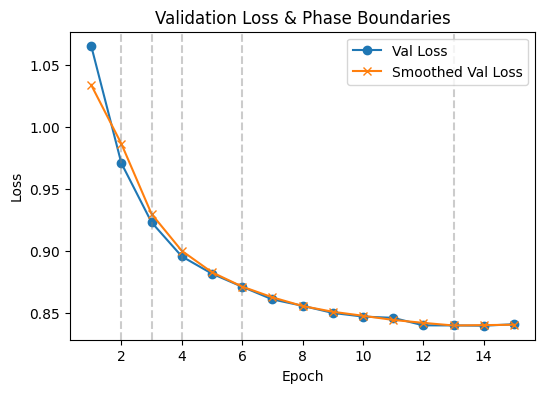

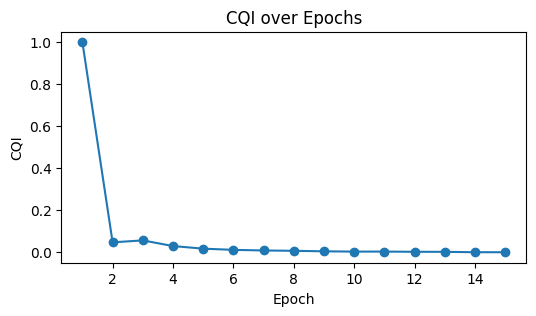

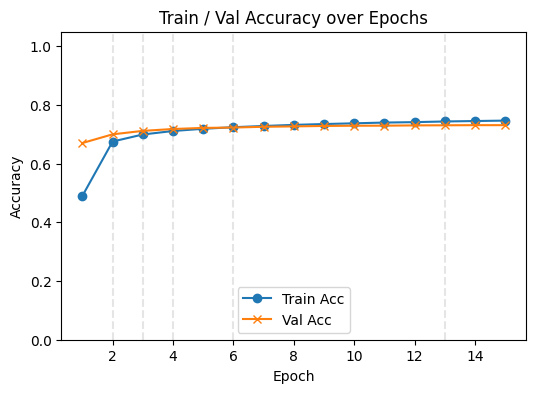

In [12]:
#@title 📉 Compute smoothed loss, CQI & define K phases + plot acc curves
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
import numpy as np

# ---- 1. 基于 val_loss 计算平滑曲线 & CQI & phase ----
val_loss = np.array(epoch_logs["val_loss"], dtype=float)
epochs = np.arange(1, len(val_loss)+1)

# Smooth validation loss
window = min(3, len(val_loss))
smoothed = uniform_filter1d(val_loss, size=window)

def compute_cqi(series, w=2):
    if len(series) < 2:
        return 1.0
    diffs = np.abs(np.diff(series[-w:]))
    return diffs.mean() if len(diffs) else 1.0

CQIs = []
for i in range(1, len(smoothed)+1):
    CQIs.append(compute_cqi(smoothed[:i], w=min(2, i)))
CQIs = np.array(CQIs)

print("Val loss:", val_loss)
print("Smoothed:", smoothed)
print("CQI:", CQIs)

# Phase boundaries via equal segments on log-smoothed loss
eps = 1e-8
log_start = np.log(smoothed[0] + eps)
log_end   = np.log(smoothed[-1] + eps)
total_drop = log_start - log_end
K = min(CFG.K_phases, len(smoothed))
per_segment = total_drop / K if K > 0 else 0.0

phase_edges = []
current_target = log_start - per_segment
for e in range(1, len(smoothed)+1):
    if np.log(smoothed[e-1]+eps) <= current_target or e == len(smoothed):
        phase_edges.append(e)
        current_target -= per_segment
        if len(phase_edges) == K:
            break

phase_edges = sorted(set(phase_edges))[:K]
while len(phase_edges) < K:
    phase_edges.append(len(smoothed))

print("K =", K, "phase edges (epoch indices):", phase_edges)

# ---- 2. 画 loss + phase 边界 ----
plt.figure(figsize=(6,4))
plt.plot(epochs, val_loss, label="Val Loss", marker="o")
plt.plot(epochs, smoothed, label="Smoothed Val Loss", marker="x")
for b in phase_edges:
    plt.axvline(b, color='gray', linestyle='--', alpha=0.4)
plt.title("Validation Loss & Phase Boundaries")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

# ---- 3. 画 CQI 曲线 ----
plt.figure(figsize=(6,3))
plt.plot(epochs, CQIs, marker="o")
plt.title("CQI over Epochs")
plt.xlabel("Epoch"); plt.ylabel("CQI"); plt.show()

# ---- 4. 画 train / val acc 曲线 ----
train_acc = np.array(epoch_logs.get("train_acc", []), dtype=float)
val_acc   = np.array(epoch_logs["val_acc"], dtype=float)

plt.figure(figsize=(6,4))
plt.plot(epochs, train_acc, label="Train Acc", marker="o")
plt.plot(epochs, val_acc,   label="Val Acc",   marker="x")
for b in phase_edges:
    plt.axvline(b, color='gray', linestyle='--', alpha=0.2)
plt.ylim(0.0, 1.05)
plt.title("Train / Val Accuracy over Epochs")
plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.legend(); plt.show()

PHASE_EDGES = phase_edges


In [22]:
import os

save_dir = "/content/drive/MyDrive/ExplainableNLP/BERT15_5"  # 可以换成你喜欢的名字
os.makedirs(save_dir, exist_ok=True)

print("💾 Saving fine-tuned model to:", save_dir)
model.save_pretrained(save_dir)
tokenizer.save_pretrained(save_dir)
print("✅ Done.")


💾 Saving fine-tuned model to: /content/drive/MyDrive/ExplainableNLP/BERT15_5
✅ Done.


In [35]:
from torch.utils.data import DataLoader
from transformers import AutoConfig, AutoModel, DataCollatorWithPadding
from tqdm.auto import tqdm
import torch
import numpy as np

def get_layer_hidden_states(
    ckpt_dir: str,
    layer_idx: int,
    dataset,
    tokenizer,
    batch_size: int = 32,
    pooling: str = "mean",
    device: str = None,
):
    """
    从某一层 BERT encoder 抽取 hidden states，并做 pooling 得到样本级表示。

    ckpt_dir: model.save_pretrained() 保存的目录
    layer_idx:
        - 0      -> embedding 层
        - 1..L   -> 第几层 encoder（超过 L 会自动用最后一层）
        - -1     -> 最后一层 encoder
    dataset: tokenized 的 HF Dataset（例如 train_enc）
    pooling: "mean" 或 "cls"
    """

    if device is None:
        device = CFG.device

    # 1. 加载配置 & 模型，打开 hidden_states
    cfg = AutoConfig.from_pretrained(ckpt_dir)
    cfg.output_hidden_states = True
    model = AutoModel.from_pretrained(ckpt_dir, config=cfg).to(device)
    model.eval()

    num_layers = model.config.num_hidden_layers  # encoder 层数（不含 embedding）
    print(f"[get_layer_hidden_states] num_hidden_layers = {num_layers}")

    # 2. DataLoader（动态 padding）
    collator = DataCollatorWithPadding(
        tokenizer=tokenizer,
        padding=True,
        return_tensors="pt",
    )
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collator,
    )

    reps = []

    # 3. 前向 & 抽取指定层 hidden states
    with torch.no_grad():
        for batch in tqdm(loader, desc=f"Extract layer {layer_idx} hidden states"):
            # 先把 tensor 移到 device
            batch = {k: v.to(device) for k, v in batch.items() if isinstance(v, torch.Tensor)}

            # 💡 BertModel 不支持 labels 这个 keyword，先删掉
            if "labels" in batch:
                batch.pop("labels")

            # 只保留模型需要的输入
            inputs = {
                k: v
                for k, v in batch.items()
                if k in ["input_ids", "attention_mask", "token_type_ids"]
            }

            outputs = model(**inputs)  # outputs.hidden_states: tuple(L+1, B, T, H)
            hidden_list = outputs.hidden_states

            # hidden_list 长度 = num_layers + 1（第 0 个是 embedding）
            L = len(hidden_list) - 1

            # ---- 关键：把 layer_idx 安全地映射到合法索引 ----
            if layer_idx is None:
                idx = -1
            elif layer_idx < 0:
                # 负数统统当作 “最后一层 encoder”
                idx = L
            elif layer_idx == 0:
                idx = 0  # embedding 层
            else:
                # 正整数：按第几层 encoder，超过 L 就 clip 到最后一层
                idx = min(layer_idx, L)

            # 第一次 batch 打印一下映射，方便 sanity check
            if not hasattr(get_layer_hidden_states, "_printed_idx_map"):
                print(f"[get_layer_hidden_states] requested layer_idx = {layer_idx}, "
                      f"num_encoder_layers = {num_layers}, "
                      f"hidden_states_len = {len(hidden_list)}, "
                      f"using idx = {idx}")
                get_layer_hidden_states._printed_idx_map = True

            hs = hidden_list[idx]  # [B, T, H]

            attn_mask = inputs.get(
                "attention_mask",
                torch.ones(hs.shape[:2], device=device, dtype=torch.long),
            )

            if pooling == "mean":
                mask = attn_mask.unsqueeze(-1).float()
                summed = (hs * mask).sum(dim=1)
                lengths = mask.sum(dim=1).clamp(min=1.0)
                pooled = summed / lengths
            elif pooling == "cls":
                pooled = hs[:, 0, :]  # [CLS]
            else:
                raise ValueError("pooling 只能是 'mean' 或 'cls'")

            reps.append(pooled.cpu())

    reps = torch.cat(reps, dim=0).numpy()
    return reps


In [38]:
# ============================
# Build FMCS dataset & save to Google Drive
# ============================

import os, json
import numpy as np

# 🔹 1. 选择用多少样本来做 FMCS 数据集
if CFG.extract_subset is not None:
    n_use = min(CFG.extract_subset, len(train_enc))
    train_extract = train_enc.select(range(n_use))
    print(f"Using {n_use} / {len(train_enc)} samples for FMCS dataset.")
else:
    train_extract = train_enc
    print(f"Using ALL {len(train_extract)} samples for FMCS dataset.")

features_list = []
labels_list   = []

# 使用你刚刚保存的 fine-tuned 模型目录
ckpt_dir = "/content/drive/MyDrive/ExplainableNLP/BERT15_5"
print("Using checkpoint dir:", ckpt_dir)

# 👉 简化版：先用 1 个 phase 调通管线
PHASE_IDS = [1]
print("PHASE_IDS for FMCS:", PHASE_IDS)

for phase_id in PHASE_IDS:
    print(f"Phase {phase_id}/{len(PHASE_IDS)} — extracting features...")

    reps = get_layer_hidden_states(
        ckpt_dir=ckpt_dir,
        layer_idx=CFG.target_layer,
        dataset=train_extract,
        tokenizer=tokenizer,
        batch_size=CFG.eval_batch_size,
        pooling=CFG.feature_pooling,
        device=CFG.device,
    )

    features_list.append(reps)
    labels_list.append(np.full((reps.shape[0],), phase_id, dtype=np.int64))

# 🔹 2. 拼接成最终的 X, y
X = np.vstack(features_list).astype("float32")  # [N, D]
y = np.concatenate(labels_list).astype("int64") # [N]

print("FMCS feature matrix:", X.shape)
print("FMCS labels:", y.shape, "classes:", np.unique(y, return_counts=True))

# 🔹 3. 保存到 CFG.drive_dir（和 Config 里保持一致）
os.makedirs(CFG.drive_dir, exist_ok=True)
feature_path = os.path.join(CFG.drive_dir, f"fmcs_features_layer{CFG.target_layer}.npy")
label_path   = os.path.join(CFG.drive_dir, f"fmcs_labels_layer{CFG.target_layer}.npy")

np.save(feature_path, X)
np.save(label_path, y)

# 虽然这里只用 1 个 phase，仍然把 PHASE_IDS 存一下，后面方便一致处理
with open(os.path.join(CFG.drive_dir, "phase_edges.json"), "w") as f:
    json.dump(PHASE_IDS, f, indent=2)

print("✅ FMCS dataset saved to:", CFG.drive_dir)
print("  features ->", feature_path)
print("  labels   ->", label_path)


Using ALL 1260000 samples for FMCS dataset.
Using checkpoint dir: /content/drive/MyDrive/ExplainableNLP/BERT15_5
PHASE_IDS for FMCS: [1]
Phase 1/1 — extracting features...
[get_layer_hidden_states] num_hidden_layers = 3


Extract layer -1 hidden states:   0%|          | 0/4922 [00:00<?, ?it/s]

FMCS feature matrix: (1260000, 256)
FMCS labels: (1260000,) classes: (array([1]), array([1260000]))
✅ FMCS dataset saved to: /content/drive/MyDrive/ExplainableNLP/FMCE_dataset_30
  features -> /content/drive/MyDrive/ExplainableNLP/FMCE_dataset_30/fmcs_features_layer-1.npy
  labels   -> /content/drive/MyDrive/ExplainableNLP/FMCE_dataset_30/fmcs_labels_layer-1.npy


## BertBIZ

# Check data


In [41]:
# ============================
# Load FMCE Stage-1 features (single file)
# ============================

import os
import numpy as np
from sklearn.model_selection import train_test_split

DATA_DIR = "/content/drive/MyDrive/ExplainableNLP/FMCE_dataset_30/"

# Feature & label file paths
feature_path = os.path.join(DATA_DIR, "fmcs_features_layer-1.npy")
label_path   = os.path.join(DATA_DIR, "fmcs_labels_layer-1.npy")

# Load data
features = np.load(feature_path)   # shape: [N, D] or [N, C, H, W]
labels   = np.load(label_path)     # shape: [N]

print("=== Raw Data Shapes ===")
print("Features shape:", features.shape)
print("Labels shape  :", labels.shape)

# ======================================================
# Dataset integrity check
# ======================================================

print("\n=== Dataset Sanity Check ===")

# 1. dtype check
print("Dtype(features):", features.dtype)
print("Dtype(labels)  :", labels.dtype)

# 2. NaN / INF check
print("NaN in features:", np.isnan(features).sum())
print("Inf in features:", np.isinf(features).sum())
print("NaN in labels:", np.isnan(labels).sum())
print("Inf in labels:", np.isinf(labels).sum())

# 3. Label range
print("Label min:", labels.min())
print("Label max:", labels.max())
print("Unique labels:", np.unique(labels))

# 4. Feature statistics
print("\nFeature Stats:")
print("Mean:", features.mean())
print("Std :", features.std())
print("Min :", features.min())
print("Max :", features.max())

=== Raw Data Shapes ===
Features shape: (1260000, 256)
Labels shape  : (1260000,)

=== Dataset Sanity Check ===
Dtype(features): float32
Dtype(labels)  : int64
NaN in features: 0
Inf in features: 0
NaN in labels: 0
Inf in labels: 0
Label min: 1
Label max: 1
Unique labels: [1]

Feature Stats:
Mean: 0.0004382038
Std : 0.83257395
Min : -3.7332115
Max : 4.0397315
